<a href="https://colab.research.google.com/github/arthuranogueira/Trabalho-de-Modelagem-Computacional/blob/main/M%C3%A9todo_do_Gradiente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

r=3.8155836121747724
h=9.148480679540238
r=3.6366724532183814, h=11.965774861194625, f=41883.732264366896, i=31235
r = 3.6367, h = 11.9658
f = 41883.73, g = 2.8367 (folga zero = restrição ativa)
iterações = 31235


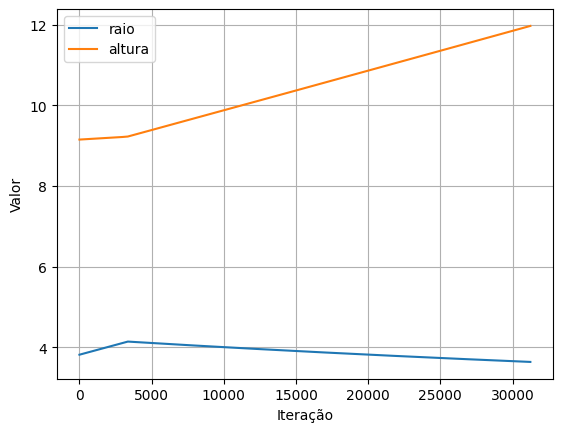

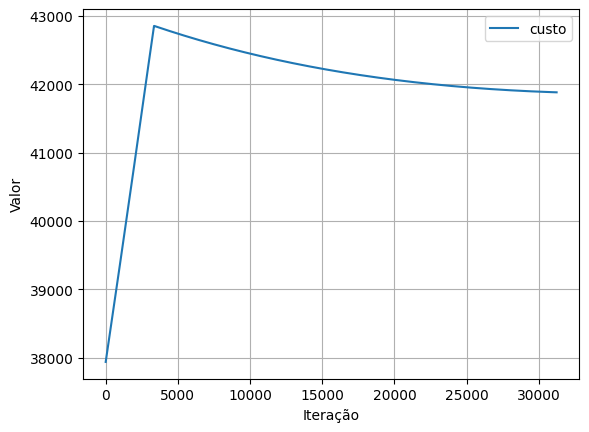

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def f(r, h):
    return 150*(np.pi*r**2) + 100*(2*np.pi*r*h) + 200*(np.pi*r**2)   # topo + lateral + base

def g(r, h):
    return 500 - np.pi*h*r**2        # >= 0 significa restrição satisfeita

def P(r, h, mi):
    return f(r, h) + mi * max(0.0, g(r, h))**2

def dPr(r, h, mi, delta=1e-5):
    return (P(r+delta, h, mi) - P(r, h, mi)) / delta

def dPh(r, h, mi, delta=1e-5):
    return (P(r, h+delta, mi) - P(r, h, mi)) / delta

def metodo_gradiente(alfa=1e-4, mi=10.0, max_iter=100000, tol=1e-6):
    r = 3.8155836121747724
    h = 9.148480679540238
    print(f'r={r}')
    print(f'h={h}')
    f_anterior = f(r, h)
    parada = np.inf
    i = 0

    conj_r=[r]
    conj_h=[h]
    conj_func=[f_anterior]
    iteracoes=[i]

    while parada > tol and i < max_iter:
        dr = dPr(r, h, mi)
        dh = dPh(r, h, mi)
        vetor_normal_gradiente=np.sqrt(dr**2+dh**2)
        if vetor_normal_gradiente > 1.0:
          dr = dr / vetor_normal_gradiente
          dh = dh / vetor_normal_gradiente

        r_novo = r - alfa * dr
        h_novo = h - alfa * dh

        # mantém dentro do domínio físico (nada de raio/altura <= 0)
        r = max(r_novo, 1e-6)
        h = max(h_novo, 1e-6)

        f_novo = f(r, h)
        parada = abs((f_novo - f_anterior) / f_anterior) * 100
        f_anterior = f_novo
        conj_r.append(r)
        conj_h.append(h)
        conj_func.append(f_anterior)
        i += 1
        iteracoes.append(i)

    print(f'r={r}, h={h}, f={f_anterior}, i={i}')

    return r, h, f_anterior, g(r, h), i, iteracoes, conj_func, conj_h, conj_r

r, h, area, folga, iters, iteracoes, conj_func, conj_h, conj_r = metodo_gradiente()
print(f"r = {r:.4f}, h = {h:.4f}")
print(f"f = {area:.2f}, g = {folga:.4f} (folga zero = restrição ativa)")
print(f"iterações = {iters}")
plt.plot(iteracoes, conj_r, label="raio")
plt.plot(iteracoes, conj_h, label="altura")
plt.xlabel("Iteração")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)
plt.show()

plt.plot(iteracoes, conj_func, label="custo")
plt.xlabel("Iteração")
plt.ylabel("Valor")
plt.legend()
plt.grid(True)
plt.show()